# Descriptive analysis of Digikala reviews

This notebook is the data audit of the project. Before any model is trained, it answers three questions:

1. Was the data read completely and correctly?
2. What is wrong with it, and what was done about each problem?
3. What does the data look like, and what does that mean for the modeling choices?

All counts are computed on the **full dataset** (6,156,289 reviews). If a plot or example uses a sample,
the cell says so and gives the seed.

The heavy lifting lives in `src/digikala_reviews/` and `scripts/`. This notebook loads their outputs,
runs a few extra checks with pandas, and explains the results.

In [1]:
import json

import matplotlib.pyplot as plt
import pandas as pd

from digikala_reviews import plotting
from digikala_reviews.config import (
    COMMENTS_CLEAN_PARQUET,
    COMMENTS_RAW_DIR,
    EXCLUDED_ROWS_PARQUET,
    REPORTS_DIR,
)
from digikala_reviews.quality import is_missing

plotting.apply_style()
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.float_format", "{:,.2f}".format)


def load_report(name):
    return json.loads((REPORTS_DIR / name).read_text(encoding="utf-8"))


ingest = load_report("data_ingest.json")
gate = load_report("quality_gate.json")
cleaning = load_report("cleaning_report.json")

## 1. Reading the data

The dataset is the public [Digikala comments and products](https://huggingface.co/datasets/RadeAI/Digikala_comments_products)
dump on Hugging Face: one CSV of reviews and one CSV of products.

`scripts/build_parquet.py` converts both files to Parquet with pandas. Every column is read as **text** and
pandas' automatic missing-value detection is turned off, so nothing is converted or dropped silently at this
point; type checks happen in the quality gate. Review bodies can contain line breaks, so records are counted
with a real CSV parser, not by counting lines. To be sure nothing was lost, the records are counted twice, with
pandas and with Python's own `csv` module, and the SHA-256 of each file is recorded so anyone can check they have
exactly the same data.

In [2]:
pd.DataFrame(
    [
        {
            "file": f["csv_file"],
            "rows (pandas)": f["rows_pandas"],
            "rows (csv module)": f["rows_csv_module"],
            "CSV (MB)": round(f["csv_size_bytes"] / 1e6),
            "Parquet (MB)": round(f["parquet_size_bytes"] / 1e6),
            "sha256": f["csv_sha256"][:16] + "...",
        }
        for f in ingest["files"]
    ]
).set_index("file")

,rows (pandas),rows (csv module),CSV (MB),Parquet (MB),sha256
file,,,,,
digikala-comments.csv,6156289,6156289,1279,451,c7a8aa3020334fde...
digikala-products.csv,1283496,1283496,259,47,0f646e1b0ba5a075...


Both counts agree: **6,156,289 reviews** and **1,283,496 product rows**, and pandas raised no parsing error.
The project brief mentions "about 7 million" reviews; the real number is 6.16 million.
The Parquet copy is about 4x smaller than the CSV and much faster to query, so everything below reads from it.

## 2. Quality gate

`scripts/run_quality_gate.py` checks the schema, missing values, numeric columns, label vocabulary, dates and
duplicates. It does not change anything: it only counts problems and keeps examples.

One thing showed up immediately: in this CSV, missing values are written as the literal text `nan`
(the file was exported with pandas). So throughout the project a value counts as **missing** when it is blank,
contains only whitespace or invisible characters, or equals `nan`.

### 2.1 Schema

In [3]:
schema = gate["comments"]["schema"]
print("Columns:", ", ".join(schema["columns"]))
print("Missing expected columns:", schema["missing_expected"] or "none")
print("Unexpected columns:", schema["unexpected"] or "none")

Columns: id, title, body, created_at, rate, recommendation_status, is_buyer, product_id, advantages, disadvantages, likes, dislikes, seller_title, seller_code, true_to_size_rate
Missing expected columns: none
Unexpected columns: none


All 15 expected columns are present. Only `body` is used as model input. `rate` and `recommendation_status`
are targets, and `product_id` is used only to split the data by product. The rest is kept for the audit.

### 2.2 Missing values

In [4]:
missing = pd.DataFrame(gate["comments"]["missing_values"]).T[["blank", "nan_token", "missing", "missing_pct"]]
missing = missing.sort_values("missing_pct", ascending=False)
missing

,blank,nan_token,missing,missing_pct
true_to_size_rate,0.00,"6,065,516.00","6,065,516.00",98.53
disadvantages,0.00,"5,744,017.00","5,744,017.00",93.30
advantages,0.00,"5,448,084.00","5,448,084.00",88.50
title,"3,241.00","2,865,062.00","2,868,303.00",46.59
recommendation_status,0.00,"894,426.00","894,426.00",14.53
seller_title,0.00,"302,181.00","302,181.00",4.91
seller_code,0.00,"302,181.00","302,181.00",4.91
body,208.00,637.00,845.00,0.01
rate,0.00,0.00,0.00,0.00
created_at,0.00,0.00,0.00,0.00


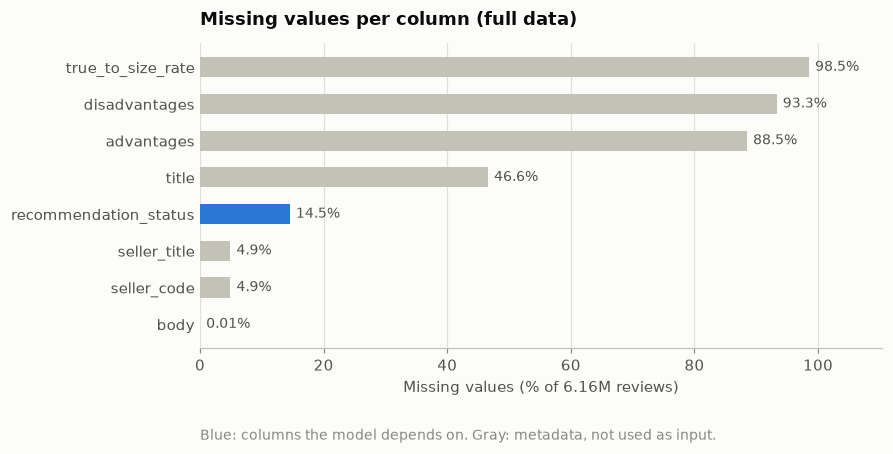

In [5]:
model_columns = {"body", "rate", "recommendation_status", "product_id"}
shown = missing[missing["missing_pct"] > 0]

fig, ax = plt.subplots(figsize=(8, 3.6))
plotting.hbar(
    ax,
    labels=list(shown.index),
    values=list(shown["missing_pct"]),
    colors=[plotting.SERIES[0] if c in model_columns else plotting.NEUTRAL for c in shown.index],
    value_labels=[f"{p:.2f}%" if p < 1 else f"{p:.1f}%" for p in shown["missing_pct"]],
    xlabel="Missing values (% of 6.16M reviews)",
)
ax.set_title("Missing values per column (full data)")
ax.text(
    0,
    -0.3,
    "Blue: columns the model depends on. Gray: metadata, not used as input.",
    transform=ax.transAxes,
    color=plotting.MUTED,
    fontsize=9,
)
plotting.save(fig, "missing_values")
plt.show()

- `body`, the only model input, is missing in just **845** reviews (0.01%): 637 are `nan` and 208 contain only
  whitespace or invisible characters. pandas would not flag those 208 as missing.
- `recommendation_status` is missing in **14.5%** of reviews (894,426). These are naturally unlabeled reviews,
  not errors. They still have a rating, so they stay useful for the rating-band task.
- `rate` and `product_id` are never missing.
- `title`, `advantages`, `disadvantages` and `true_to_size_rate` are largely empty, but none of them may be used
  as features, so this does not affect the models.

### 2.3 Is the missing seller information random?

`seller_title` and `seller_code` are missing in exactly 302,181 reviews, which is also the number of reviews
written by non-buyers. A quick cross-tab checks whether the two are the same rows.

In [6]:
sellers = pd.read_parquet(COMMENTS_RAW_DIR, columns=["is_buyer", "seller_code"])
pd.crosstab(sellers["is_buyer"], is_missing(sellers["seller_code"]).rename("seller missing"), margins=True)

seller missing,False,True,All
is_buyer,,,
False,0,302181,302181
True,5854108,0,5854108
All,5854108,302181,6156289


Every non-buyer review has no seller, and every buyer review has one. The missing seller is **structural**
(no purchase, so no seller), not random. The same question for missing recommendation labels is analyzed
in section 3.

### 2.4 Labels, ratings and dates

In [7]:
labels = pd.Series(gate["comments"]["recommendation_status"]["observed"], name="reviews").to_frame()
labels["pct"] = 100 * labels["reviews"] / labels["reviews"].sum()
labels

,reviews,pct
recommended,4162839,67.62
nan,894426,14.53
no_idea,594121,9.65
not_recommended,504903,8.20


The recommendation column uses exactly the three canonical classes plus `nan`. There are no Persian labels,
alternative spellings or extra categories, so the label mapping is the identity.

In [8]:
rate = gate["comments"]["rate"]
pd.Series(
    {
        "not a number": rate["not_a_number"],
        "inside [0, 5]": rate["in_range"],
        "outside [0, 5]": rate["out_of_range"],
        "exactly 0": rate["zero"],
        "fractional (e.g. 4.5)": rate["fractional"],
        "distinct values": rate["distinct_values"],
    },
    name="reviews",
).to_frame()

,reviews
not a number,0
"inside [0, 5]",6156288
"outside [0, 5]",1
exactly 0,529098
fractional (e.g. 4.5),228128
distinct values,177


In [9]:
pd.DataFrame(rate["out_of_range_examples"])

,src_row,id,product_id,rate,recommendation_status,body
0,4369260,38631814,5095301,2500.0,recommended,کوچک و با کیفیت


Every rating is a valid number. Only **one** falls outside 0 to 5: a rating of 2500 on a short positive review.
It could be a typo for 2.5, but guessing would be inventing data, so it is marked invalid for the rating-band
task and kept for the recommendation task.

Two numbers need a closer look later: **529,098 ratings of exactly 0** and **228,128 fractional ratings**.
Both are analyzed in section 3, because they directly affect how the `low` band should be defined.

In [10]:
dates = gate["comments"]["created_at"]
print("Rows not matching 'day month year':", dates["not_matching_format"])
print("Unknown month names:", dates["unknown_month"])
pd.Series(dates["rows_per_year"], name="reviews").to_frame().T

Rows not matching 'day month year': 0
Unknown month names: 0


,1395,1396,1397,1398,1399,1400,1401,1402
reviews,3575,6357,16693,138645,684321,1253484,2165894,1887320


Dates are Persian (Jalali) text such as `23 شهریور 1402`. All 6.16M dates have a valid format and month name,
and they span the years **1395 to 1402** (roughly 2016 to early 2024). Most reviews were written in 1400 to 1402.

### 2.5 Duplicate ids

In [11]:
dup = gate["comments"]["duplicate_ids"]
pd.Series(
    {
        "ids that appear more than once": dup["duplicated_ids"],
        "extra rows": dup["extra_rows"],
        "groups: all copies identical": dup["groups_fully_identical"],
        "groups: only metadata differs (likes, seller, ...)": dup["groups_metadata_only"],
        "groups: body, rating or label differs": dup["groups_content_differs"],
    },
    name="count",
).to_frame()

,count
ids that appear more than once,3226
extra rows,3229
groups: all copies identical,1318
"groups: only metadata differs (likes, seller, ...)",1663
"groups: body, rating or label differs",245


In [12]:
pd.DataFrame(dup["content_conflict_examples"])

,src_row,id,product_id,rate,recommendation_status,likes,body
0,3561860,12862914,2670905,5.0,recommended,0,کرم خوبیه\r\nپیشنهاد میکنم
1,3996799,12862914,2670905,0.0,recommended,0,کرم خوبیه\r\nپیشنهاد میکنم
2,2831183,17111330,2952419,0.0,not_recommended,4,حتی تو تخفیف هم ارزش خریدن نداره
3,2868980,17111330,2952419,1.0,not_recommended,4,حتی تو تخفیف هم ارزش خریدن نداره
4,3715097,22662971,853680,5.0,recommended,0,خوب بودخرید رو توصیه میکنم
5,3965442,22662971,853680,0.0,recommended,0,خوب بود
6,304459,24446421,2602504,4.0,recommended,0,خیلی جذب خوبی داره.و راحته
7,3835164,24446421,2602504,4.0,recommended,0,خیلی جذب خوبی داره.و راحته.حساسیت زا هم نیستن.


3,226 ids appear more than once. Most groups are harmless: either the copies are identical, or only counters
like `likes` differ, which suggests the data was scraped more than once. But **245 groups disagree on the
content itself**. In the examples above, the same review text has a rating of 5 in one copy and 0 in the other,
while the label stays `recommended`. That is a first hint that a rating of 0 may mean "no rating recorded"
rather than a bad rating.

A side note: an earlier exploratory count found 2,679 duplicated ids. That script read the file in chunks and only
compared each chunk against previous ones, so duplicates within the same chunk were missed. The extra-row count
(3,229) matches the number of unique ids found there, which confirms the corrected figure.

Comparing copies after stripping whitespace matters: one id has two copies that differ only by a trailing line break, with the same rating and label. Those copies count as the same review, not as a conflict.

### 2.6 Products file

In [13]:
products = gate["products"]
pd.Series(
    {
        "product rows": products["rows"],
        "distinct product ids": products["distinct_ids"],
        "ids with more than one row": products["ids_with_several_rows"],
        "ids with conflicting categories": products["ids_with_conflicting_category"],
        "products that have reviews": products["reviewed_products"],
        "reviewed products missing from the file": products["reviewed_products_missing_from_file"],
    },
    name="count",
).to_frame()

,count
product rows,1283496
distinct product ids,948352
ids with more than one row,258718
ids with conflicting categories,757
products that have reviews,331599
reviewed products missing from the file,0


The products file has repeated rows (up to 11 per id), but every reviewed product is in it. It is only used to
attach a category to each product for later error analysis, never as a model feature. When a product has
several rows, the most frequent category is used, and the 757 products with conflicting categories are marked
as ambiguous.

## 3. Cleaning

`scripts/build_clean.py` applies the rules below and writes `data/interim/comments_clean.parquet`.
The review text is copied unchanged; normalization is done later, in one shared function.

| Rule | Problem | Decision | Why |
|---|---|---|---|
| P1 | How missing values look | blank, whitespace only, or `nan` | Evidence from the quality gate |
| P2 | Empty review body (845) | Excluded from all tasks | The text is the only input |
| P3 | Missing recommendation label | Kept; used for rating band only | Required by the protocol |
| P4 | Rating outside 0 to 5 (1) | Rating band left empty; row kept | No silent correction |
| P5 | Identical copies of an id | Keep the first copy | No information lost |
| P6 | Copies differing only in metadata | Keep the first copy | Metadata is not used |
| P7 | Copies disagreeing on text, rating or label | Exclude all copies | The true label is unknown |

Every excluded row is saved with its reason in `data/interim/excluded_rows.parquet`.

In [14]:
steps = pd.Series({"raw rows": cleaning["rows_raw"]})
for reason, n in cleaning["rows_excluded"].items():
    steps[f"excluded: {reason}"] = -n
steps["clean rows"] = cleaning["rows_clean"]
steps.to_frame("rows")

,rows
raw rows,6156289
excluded: duplicate_id_extra_copy,-2984
excluded: missing_body,-845
excluded: duplicate_id_conflict,-490
clean rows,6151970


In [15]:
# The first two excluded rows for each reason
excluded = pd.read_parquet(EXCLUDED_ROWS_PARQUET)
excluded.groupby("exclusion_reason").head(2).sort_values("exclusion_reason")

,src_row,id,exclusion_reason
2,9764,52238912,duplicate_id_conflict
4,14206,53498321,duplicate_id_conflict
23,91337,6474081,duplicate_id_extra_copy
29,104126,54460135,duplicate_id_extra_copy
0,6148,20431507,missing_body
1,8758,45984959,missing_body


After cleaning, **6,151,970 reviews** remain, each id exactly once (the script checks this and stops if any
duplicate is left).

**The zero-rating question is still open.** The protocol bands are kept for now (a rating of 0 is `low`), but
every zero is flagged with `rate_is_zero`. The table below shows why this decision matters.

In [16]:
clean = pd.read_parquet(COMMENTS_CLEAN_PARQUET, columns=["rating_band", "rate_is_zero"])
clean["rating_band"] = clean["rating_band"].fillna("invalid")

zeros = clean.groupby("rating_band")["rate_is_zero"].agg(reviews="size", zero_ratings="sum")
zeros["zero_pct"] = 100 * zeros["zero_ratings"] / zeros["reviews"]
zeros.loc[["low", "medium", "high", "invalid"]]

,reviews,zero_ratings,zero_pct
rating_band,,,
low,1091627,528914,48.45
medium,1058360,0,0.00
high,4001982,0,0.00
invalid,1,0,0.00


Almost **half of the `low` band** consists of ratings of exactly 0. If those zeros really mean "no rating given",
nearly half of the `low` labels would be wrong. Section 3 tests this before the bands are finalized.